# Value at Risk

Value at Risk - VaR - is one of the most important metrics that is used to measures the risk associated with a financial position or a portfolio of financial instruments. VaR can be defined as the maximum loss with a confidence level over a predetermined period. Let's say that the 1-day 95% VaR of a portfolio is  $\$100$. This means that 95$%$ of the time, it is expected that - under normal market conditions - we will not lose more than $\$100$ by holding our portfolio over one day.

Three approaches that are commonly used in the industry are

- Parametric
- Historical
- Monte Carlo

### Import Libraries

In [87]:
# data manipuation
import pandas as pd
import numpy as np

# data visualization
import matplotlib as mpl
import matplotlib.pyplot as plt

import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

# statistical analysis & optimizatio
import scipy.stats as scs
import scipy.optimize as sco

# scikit learn(sklearn) package is used primarily for machine learning
import sklearn

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf

# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os
dir_path = r'C:\Admin\CQF Course\Python Labs\Value at Risk & GARCH'

# Image package
from PIL import Image

# tabulate package
from tabulate import tabulate

# ARCH Toolbox
from arch import arch_model

In [48]:
# Plot settings
plt.style.use('dark_background')
mpl.rcParams['figure.figsize'] = [24.0, 8.0]
mpl.rcParams['font.size'] = 10
mpl.rcParams['lines.linewidth'] = 2.0
mpl.rcParams['grid.color'] = 'black'

### Retrive Data

In [49]:
tickers = ['AMD','CSCO','INTC','INTU','NVDA']

df = yf.download(tickers = tickers, start = '2017-01-03', end = '2021-12-30', progress=False)['Adj Close']


### Calculate Returns

In [50]:
df_returns = df.pct_change().dropna()

### Visualize daily returns

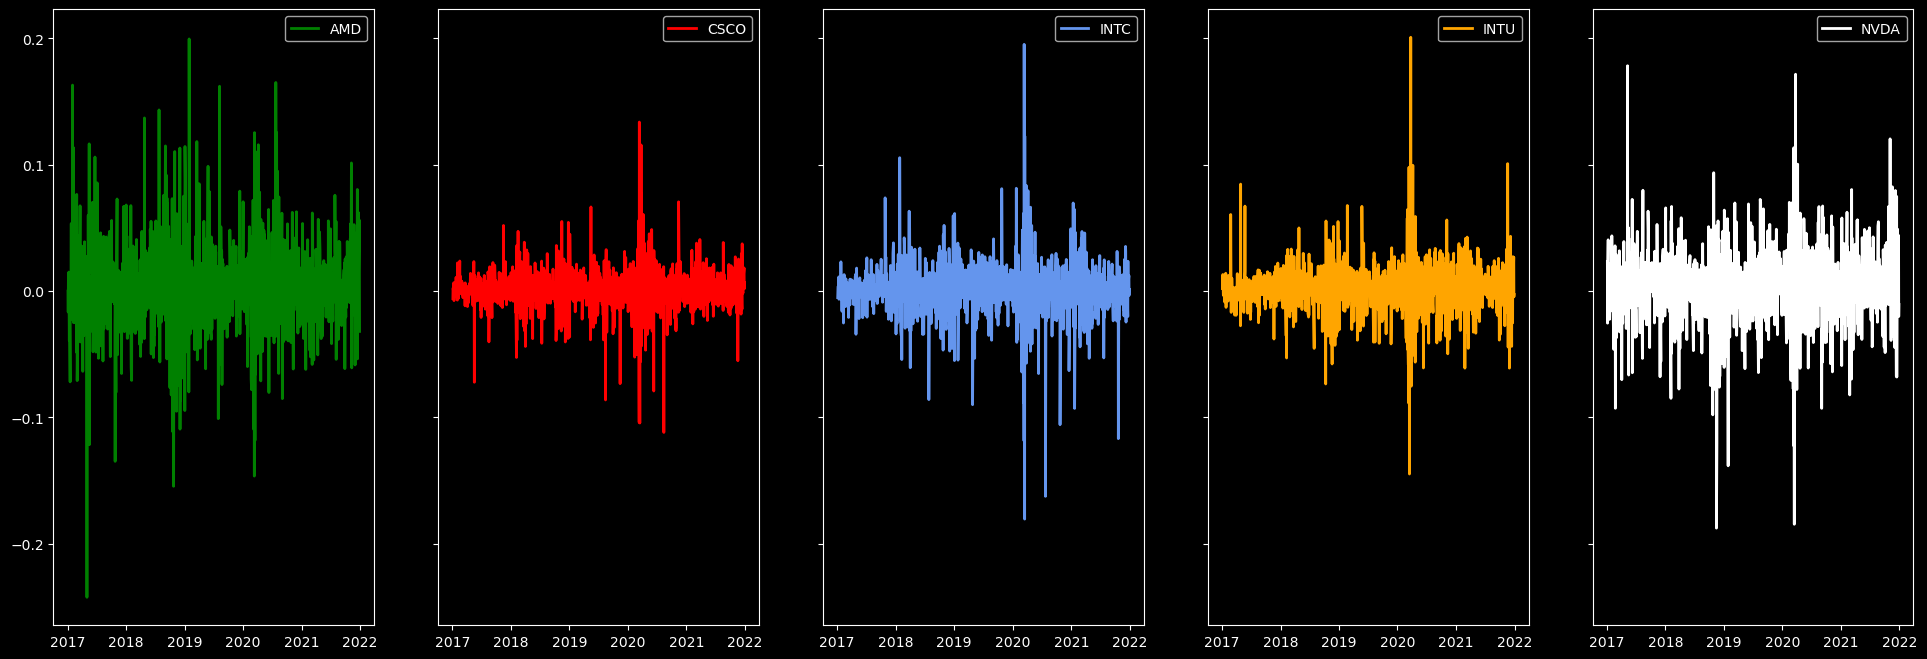

In [51]:
fig,ax = plt.subplots(ncols = len(tickers),sharey = True)
colors = ['green', 'red', 'cornflowerblue', 'orange', 'white']

for i in range(len(tickers)):
    ax[i].plot(df_returns.iloc[:,i],label = tickers[i],color = colors[i] )
    ax[i].legend()


## Parametric VaR

The Variance-covariance is a parametric method which assumes (almost always) that the returns are normally distributed. In this method, we first calculate the mean and standard deviation of the returns to derive the risk metric. Based on the assumption of normality, we can generalise, 

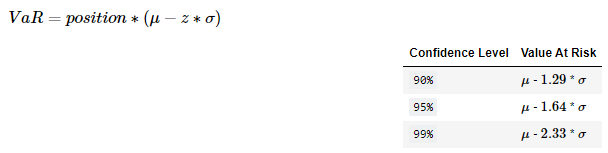

In [52]:
Image.open(os.path.join(dir_path,'VaR.png'))

where,  $\mu$ is the return,  $\sigma$ is the volatility and  z is the number of standard deviation from the mean. you can notice many different notations for VaR formula, in short one of the terms will be negative and other positive

In [53]:
# Calculate mean and standard deviation 
mean = df_returns['AMD'].mean()
stddev = df_returns['AMD'].std()

# Calculate VaR at difference confidence level
VaR_90 = scs.norm.ppf(1-0.9,loc = mean, scale = stddev)       # scs.norm.ppf() - Percent point function: invesrse of cdf
VaR_95 = scs.norm.ppf(1-0.95,loc = mean, scale = stddev)
VaR_99 = scs.norm.ppf(1-0.99,loc = mean, scale = stddev)

# VaR results in tabular format

header = ['Confidence Level', 'Value at Risk']            
data = [['0.9',VaR_90],['0.95',VaR_95],['0.99',VaR_99]]

print(tabulate(tabular_data=data, headers=header))             # tabulate()

  Confidence Level    Value at Risk
------------------  ---------------
              0.9        -0.0427298
              0.95       -0.0555996
              0.99       -0.0797413


### Calculate VaR - Iterate over Symbols

In [54]:
# calculate VaR function


def calculate_var(df):
    
    var_df = pd.DataFrame()
    cols_list = list(df.columns)
    
    for cl in [90,95,99]:
        for col in cols_list:
            var_df.loc[cl,col] = 100*scs.norm.ppf(1-(cl/100),loc = df.loc[:,col].mean(),scale = df.loc[:,col].std())
            
    return var_df
        

In [55]:
calculate_var(df_returns)

,AMD,CSCO,INTC,INTU,NVDA
90,-4.2730,-2.1014,-2.7404,-2.3417,-3.5579
95,-5.5600,-2.7214,-3.5348,-3.0509,-4.6350
99,-7.9741,-3.8846,-5.0250,-4.3813,-6.6555


### Qustions

Now, let's assume that we have 1,000 shares of AMD's stock on Dec 30, 2021. What is the maximum loss next day with a confidence level of 99%?

In [56]:
position = 1000*df['AMD'].iloc[-1]

# method 1
max_loss_1 = position*VaR_99

#method 2
max_loss_2 = position*(mean - scs.norm.ppf(0.99)*stddev)

max_loss_1,max_loss_2

(-11822.437316816422, -11822.437316816422)

## Historical VaR

Asset returns do not necessarily follow a normal distribution. An alternative is to use sorted returns to evaluate a VaR. This method uses historical data where returns are sorted in ascending order to calculate maximum possible loss for a given confidence level.

In [57]:
# Use quantile function for Historical VaR
# quantile at 1% confidence level means 1only 1% observations below it

hVaR_90 = df_returns['AMD'].quantile(q= 0.1)                                    # df.quantile(), no percentile method
hVaR_95 = df_returns['AMD'].quantile(q =0.05)
hVaR_99 = df_returns['AMD'].quantile(q =0.01)

htable = [['90%', hVaR_90],['95%', hVaR_95],['99%', hVaR_99]]
print(tabulate(htable,headers=header))

Confidence Level      Value at Risk
------------------  ---------------
90%                      -0.0334729
95%                      -0.0504151
99%                      -0.0887632


## MonteCarlo VaR

The Monte Carlo simulation approach has a number of similarities to historical simulation. It allows us to use actual historical distributions rather than having to assume normal returns. As returns are assumed to follow a normal distribution, we could generate n simulated returns with the same mean and standard deviation (derived from the daily returns) and then sorted in ascending order to calculate maximum possible loss for a given confidence level.

In [58]:
# set seed for reproducibility
np.random.seed  =42

n_sims = 5000

# simulated returns
sim_returns = np.random.normal(loc = mean, scale = stddev,size = n_sims)

MCVaR_90 = np.quantile(a = sim_returns,q =0.1)            # np.quantile() 
MCVaR_95 = np.quantile(a = sim_returns,q =0.05)
MCVaR_99 = np.quantile(a = sim_returns,q =0.01)

MCVaR_90 = np.percentile(a = sim_returns,q =10)           # np.percentile() 
MCVaR_95 = np.percentile(a = sim_returns,q =5)
MCVaR_99 = np.percentile(a = sim_returns,q =1)

mctable = [['90%', MCVaR_90],['95%', MCVaR_95],['99%', MCVaR_99]]
print(tabulate(mctable,headers=header))

Confidence Level      Value at Risk
------------------  ---------------
90%                      -0.0421382
95%                      -0.0558932
99%                      -0.080325


## Scaling VaR

Now, let's calculate VaR over a 5-day period. To scale it, multiply by square root of time. where,  T is the horizon or forecast period.

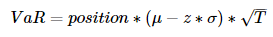

In [59]:
Image.open(os.path.join(dir_path,'scaling_var.png'))

In [60]:
forecast_days = 5
f_VaR_90 = VaR_90*np.sqrt(forecast_days)
f_VaR_95 = VaR_95*np.sqrt(forecast_days)
f_VaR_99 = VaR_99*np.sqrt(forecast_days)

ftable = [['90%', f_VaR_90],['95%', f_VaR_95],['99%', f_VaR_99] ]
fheader = ['Confidence Level', '5-Day Forecast Value At Risk']
print(tabulate(ftable,headers=fheader))

Confidence Level      5-Day Forecast Value At Risk
------------------  ------------------------------
90%                                     -0.0955468
95%                                     -0.124325
99%                                     -0.178307


Text(0.5, 1.0, 'VaR_95 Scaled by Time')

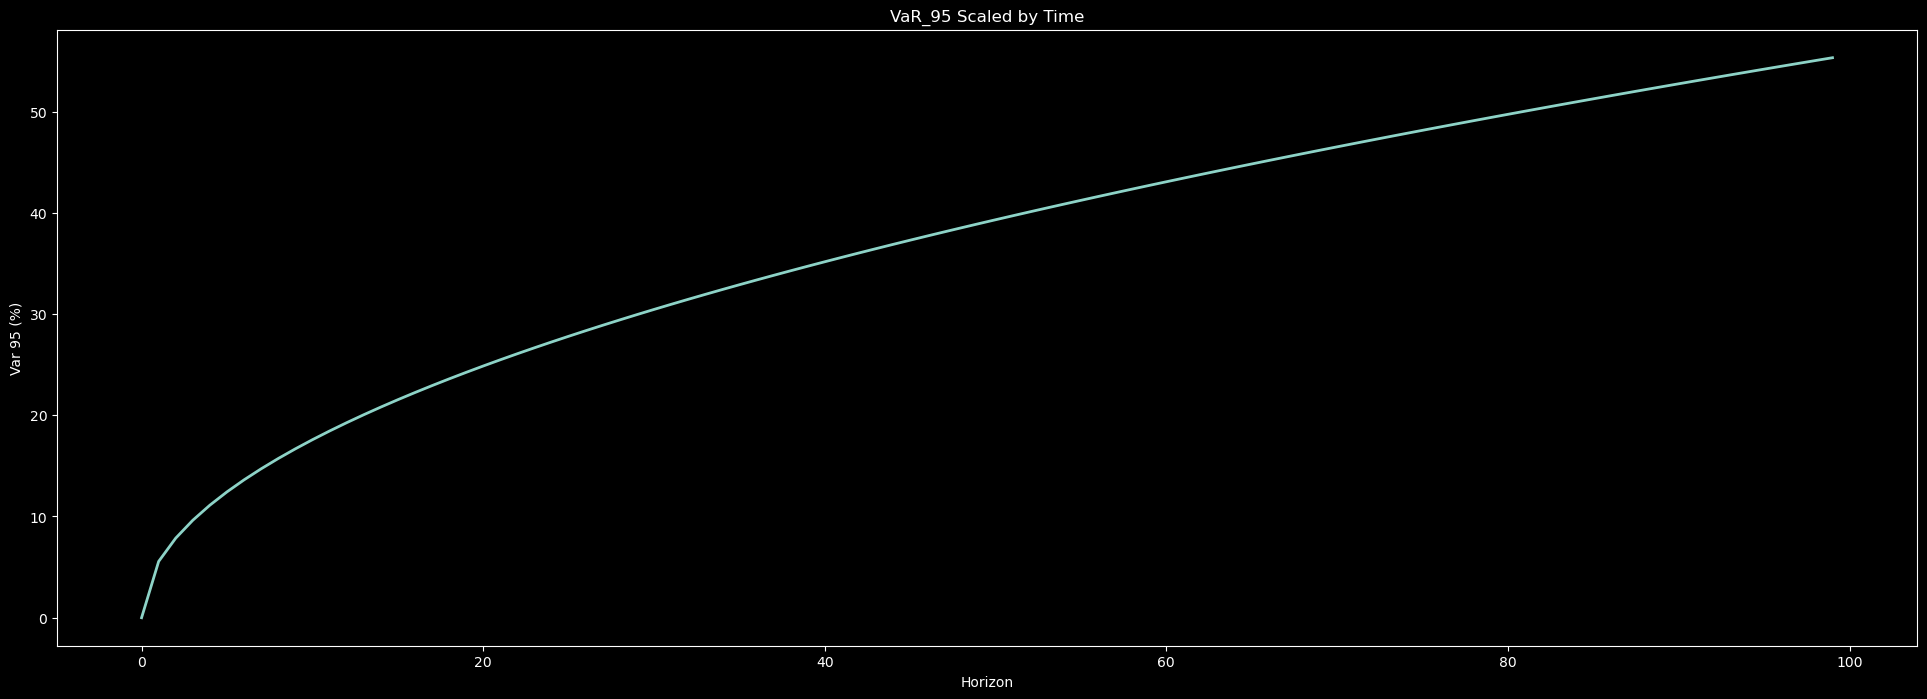

In [61]:
# Scaled VaR over different time horizon

time = range(100)
scaled_var = -100*np.array([VaR_95*np.sqrt(x) for x in time])

plt.plot(time,scaled_var,)
plt.xlabel('Horizon')
plt.ylabel('Var 95 (%)')
plt.title('VaR_95 Scaled by Time')

## Expected ShortFall

VaR is a reasonable measure of risk if assumption of normality holds. Else, we might underestimate the risk if we observe a fat tail or overestimate the risk if tail is thinner. Expected shortfall or Conditional Value at Risk - CVaR - is an estimate of expected shortfall sustained in the worst 1 - x% of scenarios. It is defined as the average loss based on the returns that are lower than the VaR threshold. Assume that we have n return observations, then the expected shortfall is:

where,  R is returns,  hVaR is historical VaR and  cl is the confidence level.

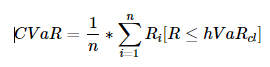

In [62]:
Image.open(os.path.join(dir_path,'ES.png'))

In [63]:
# calculate CVaR
CVaR_90 = df_returns['AMD'].loc[df_returns['AMD'] <= hVaR_90].sum()
CVaR_95 = df_returns['AMD'].loc[df_returns['AMD'] <= hVaR_95].sum()
CVaR_99 = df_returns['AMD'].loc[df_returns['AMD'] <= hVaR_99].sum()

ctable = [['90%', CVaR_90],['95%', CVaR_95],['99%', CVaR_99] ]
cheader = ['Confidence Level', 'Conditional Value At Risk']
print(tabulate(ctable,headers=cheader))

Confidence Level      Conditional Value At Risk
------------------  ---------------------------
90%                                    -7.38356
95%                                    -4.84095
99%                                    -1.62986


## Portfolio VaR

If we know the returns and volatilities of all the assets in the portfolio, we can calculate the VaR for the whole portfolio. We will now derive VaR of an equal weighted portfolio of FAANG stocks. we are using parametric VaR approach

In [64]:
# these are taken from minimum variance portfolio
wts = [0., 57.71, 13.14, 29.16, 0.0]
port_wts = np.array(wts)[:,np.newaxis]

# portfolio retutn
rets = np.array(df_returns.mean())[:,np.newaxis]
port_rets = np.linalg.multi_dot([port_wts.T,rets])

# portfolio volatility
covr = np.array(df_returns.cov())
port_vols =  np.linalg.multi_dot([port_wts.T,covr,port_wts])

In [65]:
# Calculate Portfolio VaR at difference confidence level

pVaR_90 = scs.norm.ppf(loc = port_rets, scale = port_vols,q = 0.1)
pVaR_95 = scs.norm.ppf(loc = port_rets, scale = port_vols,q = 0.05)
pVaR_99 = scs.norm.ppf(loc = port_rets, scale = port_vols,q = 0.01)

ptable = [['90%', pVaR_90],['95%', pVaR_95],['99%', pVaR_99]]
print(tabulate(ptable,headers=header))

Confidence Level      Value at Risk
------------------  ---------------
90%                        -3.12993
95%                        -4.04681
99%                        -5.76673


### Benefit of Diversification

In [66]:
# assume we have 1000 shares of each stock
# confidence level 95%

i = 0
port_position =0

for stock in tickers:
    position = df[stock].iloc[-1]*1000*wts[i]
    var = calculate_var(df_returns).loc[95,stock]
    i+=1
    
    port_position += position
    print('holding vale in stock {} is {:4.4f} and VaR is {:4.4f}%'.format(stock,position,var))
    
    
print('holding vale in portfolio is {:4.4f} and VaR is {:4.4f}%'.format(port_position,pVaR_95.flatten()[0]))

holding vale in stock AMD is 0.0000 and VaR is -5.5600%
holding vale in stock CSCO is 3417627.6579 and VaR is -2.7214%
holding vale in stock INTC is 638236.3122 and VaR is -3.5348%
holding vale in stock INTU is 18592009.4971 and VaR is -3.0509%
holding vale in stock NVDA is 0.0000 and VaR is -4.6350%
holding vale in portfolio is 22647873.4672 and VaR is -4.0468%


# GARCH

## Volatility

Asset price volatility is central to derivatives pricing. It is defined as measure of price variability over certain period of time. In essence, it describes standard deviation of returns. There are different types of volatility: Historical, Implied, Forward. In most cases, we assume volatility to be constant, which is clearly not true and numerous studies have been dedicated to estimate this parameter, both in academia and industry.

Volatility estimation by statistical means assume equal weights to all returns measured over the period. We know that over 1-day, the mean return is small as compared to standard deviation. If we consider a simple m-period moving average, where  $\sigma_n$ is the volatility of return on day n, then with  $\bar{u}$ ≈ 0, we have

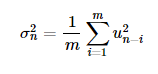

In [67]:
Image.open(os.path.join(dir_path,'arch_1.png'))

However, any large return within this n period will elevate the volatility until it drops out of the sample. Further, we observe volatility is mean reverting and tends to vary about a long term mean. To address this effect, we adopt to the weighting schemes.

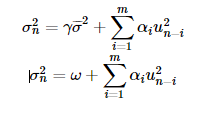

In [68]:
Image.open(os.path.join(dir_path,'arch_2.png'))

where,  $\omega = \gamma \bar{\sigma}^2$ and weights must sum to 1.

This is known as **Autoregressive Conditional Heteroscedastic model**.

## ARCH

Autoregressive models are a statistical technique involving a regression of lagged values where the model suggests that past values can help forecast future values of the same variable. Within the model, a time series is the dependent variable and lagged values are the independent variables.

The ARCH model, was originally developed by Robert Engle in 1982 to measure the dynamics of inflation uncertainty. **Conditional heteroskedasticity(volatility) refers to the notion that the next period’s volatility is conditional on the volatility in the current period as well as to the time varying nature of volatility**. However, given the volatility dynamics, this model fail to fully capture the persistence of volatility.

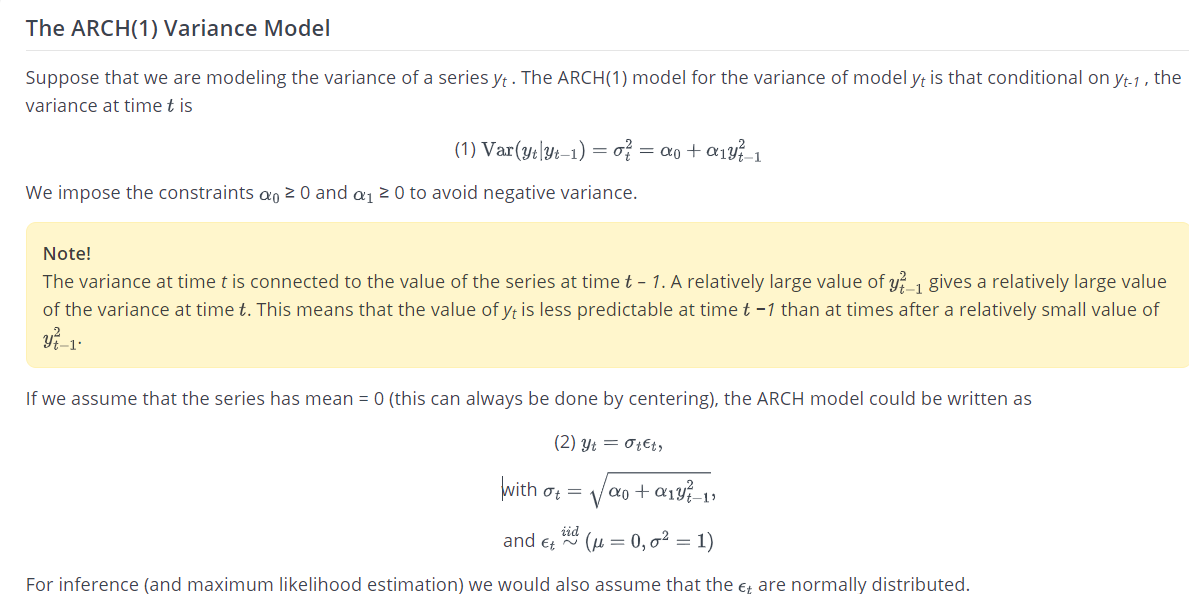

In [86]:
Image.open(os.path.join(dir_path,'arch_3.png'))

## GARCH

To address the shortcoming, ARCH has been extended to a generalised framework where we add volatility as a forecasting feature by adding previous variance. This method is popularly known as **Generalized ARCH or GARCH model**.
where,  p and  q are lag length.

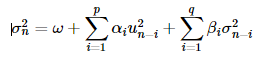

In [69]:
Image.open(os.path.join(dir_path,'garch_1.png'))

**GARCH(1,1)** is then represented as,

$$ (\sigma_n)^2 = \omega + \alpha u_{n-1}^2 + \beta \sigma_{n-1}^2$$

where,  α + β < 1 and  γ + α + β = 1 as weight applied to long term variance cannot be negative.
**where,  ω/(1−α−β) is the long-run variance**.The GARCH model is a way of specifying the dependence of the time varying nature of volatility. The model incorporates changes in the fluctuations in volatility and tracks the persistence of volatility as it fluctuates around its long-term average and are exponentially weighted.

To model GARCH or the conditional volatility, we need to derive  ω,  α,  β by maximizing the likelihood function.

### Retrieve Data

In [70]:
df = yf.download(tickers = '^GSPC', start = '2009-01-02', end = '2020-12-31', progress=False)['Adj Close']

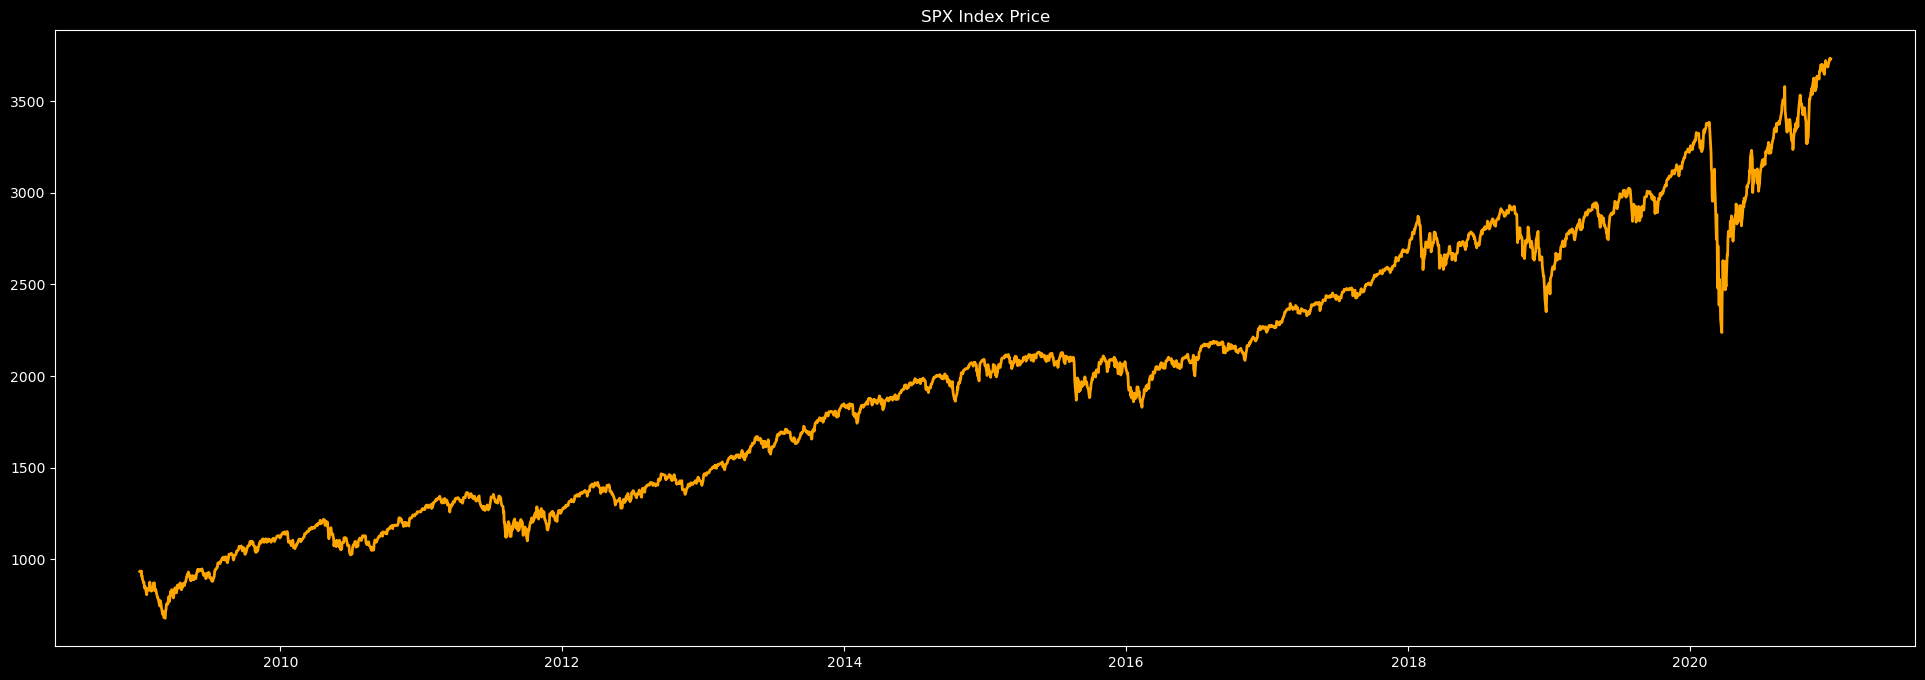

In [71]:
plt.plot(df,color = 'orange')
plt.title('SPX Index Price')
plt.show()

### Calculate & Plot log Returns

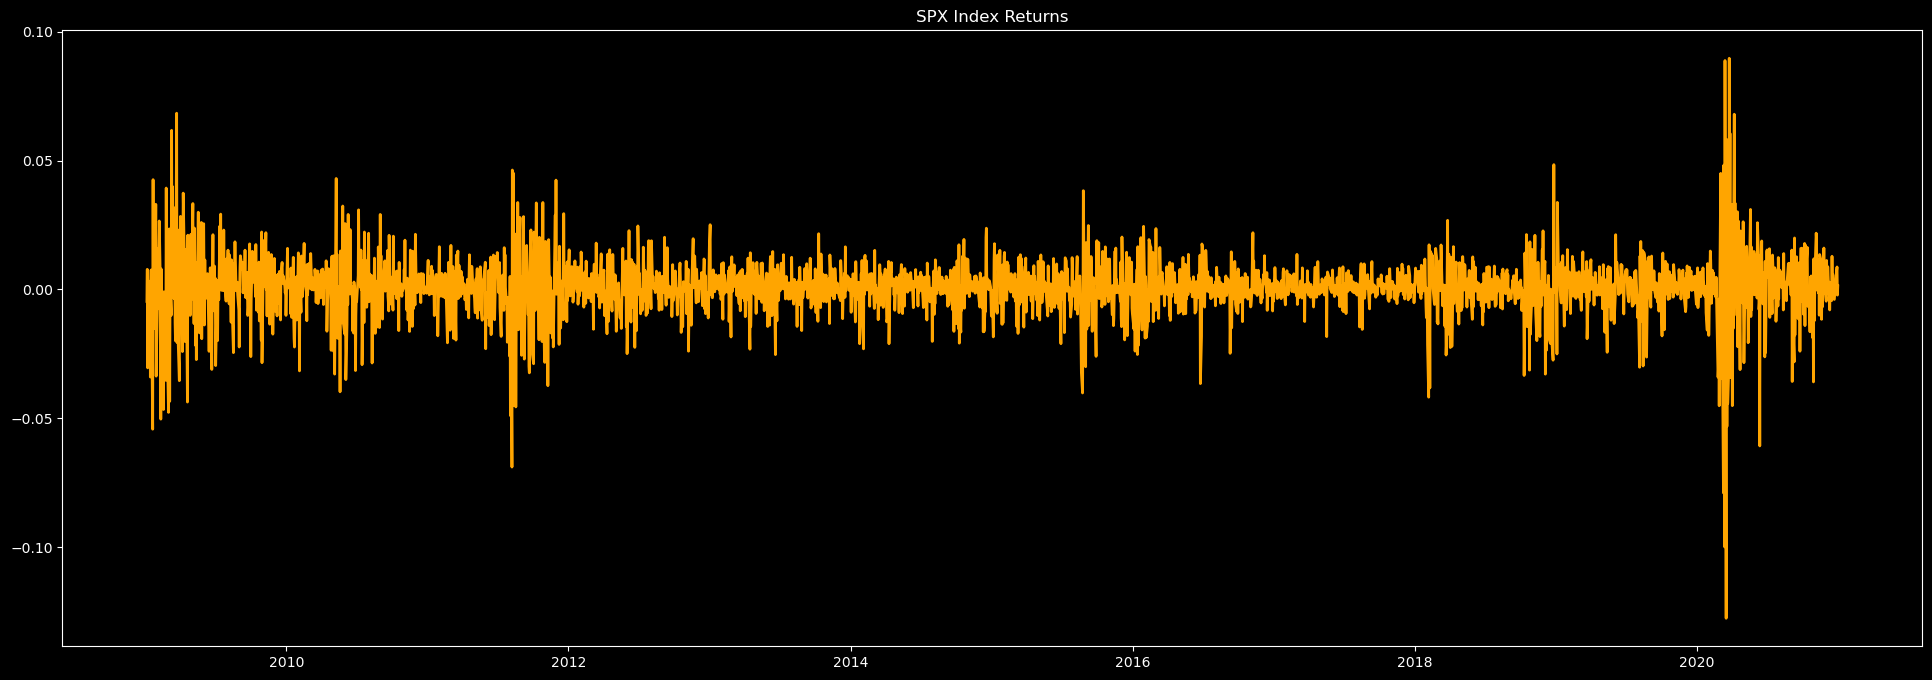

In [72]:
returns = np.log(df).diff(periods = 1).dropna()

plt.plot(returns,color='orange')
plt.title('SPX Index Returns')
plt.show()

## Numerical Optimization

We will use Numerical optimization to maximize the likelihood estimation. Numerical optimization is typically implemented to find the minimum of a function rather than the maximum and the function to be minimize is called an objective function. For maximum likelihood estimation, we simply define a negative log likelihood as our objective function.

### GARCH

Advantage of using a GARCH method when compared to EWMA is the inclusion of long term variance or volatility as a forecasting feature

In [73]:
# GARCH(1,1) function
# don't define var list outside function, why !!!

def garch(omega,alpha,beta,returns):
    
    var = []
    for i in range(len(returns)):
        if i ==0:
            var.append(omega/(1-alpha-beta))
        else:
            var.append(omega + alpha*(returns[i-1]**2) + beta*var[i-1])
            
    return np.array(var)


## Maximum Likelihood Estimation

Maximum Likeihood Estimation (MLE) is a statistical method used for fitting the data to a model. When using MLE, we first assume a distribution (ie., a parametric model) and then try to determine the model parameters. **To estimate GARCH(1,1) parameters, we assume distribution of returns conditional on variance are normally distributed.**

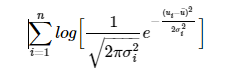

In [75]:
Image.open(os.path.join(dir_path,'maximum_likelihood.png'))

In [76]:
def likelihood(params,returns):
    omega = params[0]
    alpha = params[1]
    beta = params[2]
    
    variance = garch(omega,alpha,beta,returns)
    
    log_likehihood =[]
    
    for i in range(len(returns)):
        log_likehihood.append(np.log(scs.norm.pdf(returns[i],loc = 0, scale = np.sqrt(variance[i]))))
        
    return -np.sum(np.array(log_likehihood))
                            

### Optimization

Next, to optimize the GARCH parameters, we will use the minimize function from scipy optimization module. The objective function here is a function returning maximum log likelihood and the target variables are GARCH parameters.

Further, we use the Nelder–Mead method also known as downhill simplex method which is a commonly applied to numerical method to find the minimum or maximum of an objective function in a multidimensional space. The simplex algorithm is probably the simplest way to minimize a fairly well-behaved function. It requires only function evaluations and is a good choice for simple minimization problems. The downside to this method is it may take longer to find the minimum as it does not use any gradient evaluations.

In [77]:
initial_params = [np.var(returns),0.1,0.8]
optimized_params = sco.minimize(fun = likelihood,x0 =initial_params,args = returns,method='Nelder-Mead' )

omega = optimized_params['x'][0]
alpha = optimized_params['x'][1]
beta = optimized_params['x'][2]


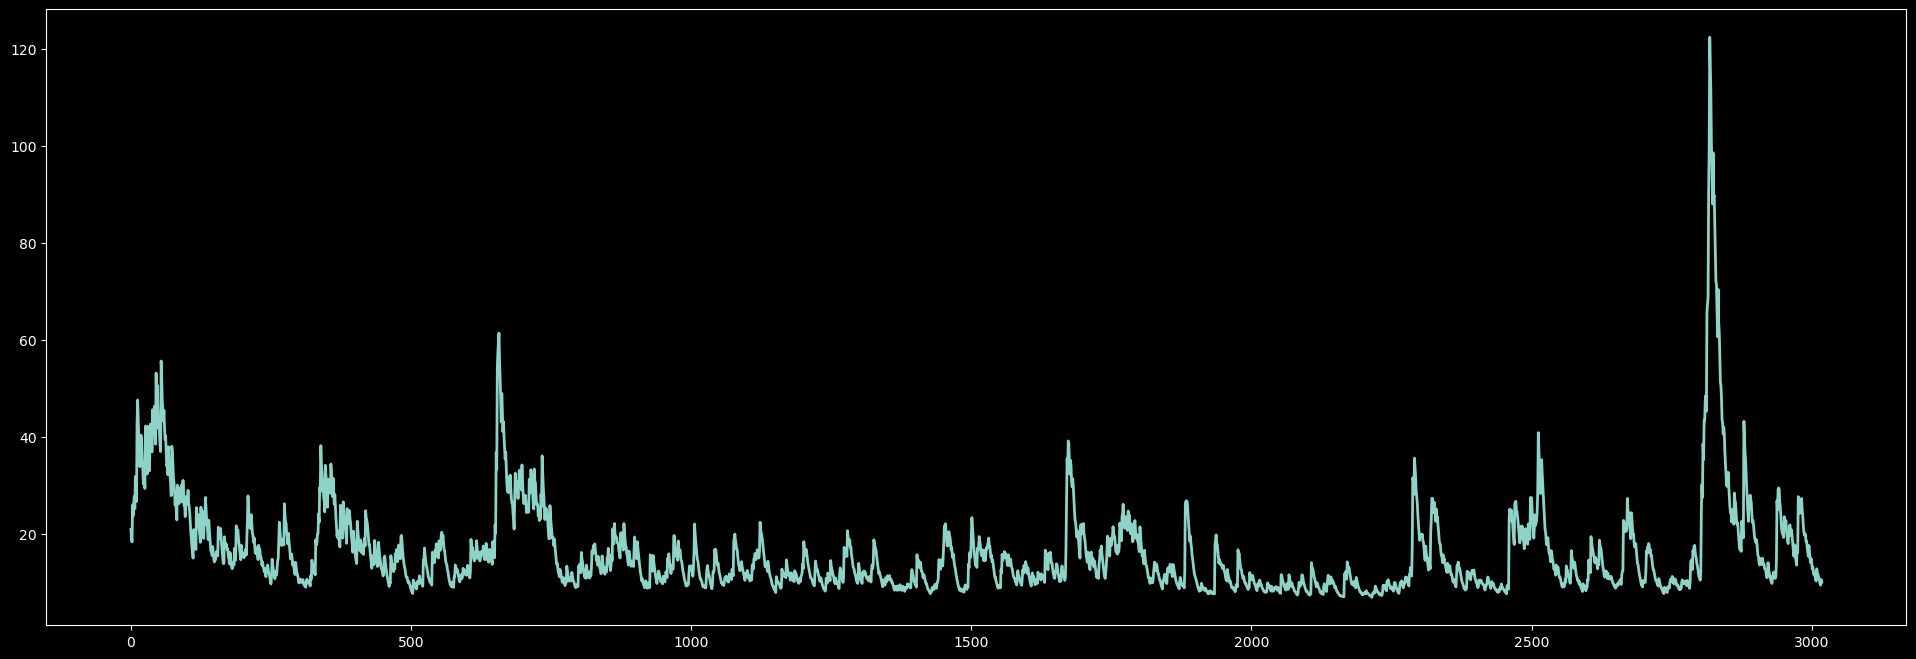

In [78]:
# to calculate and plot annualized conditional volatility

garch_var = garch(omega, alpha, beta,returns)
garch_vol = np.sqrt(garch_var)
garch_vol_annual = garch_vol*np.sqrt(252)*100

plt.plot(garch_vol_annual)
plt.show()

### N-day Forecast

Extending the GARCH(1,1) model to forecast future volatility, we can derive the n-days ahead forecast using the following equation.

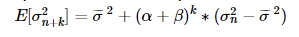

In [79]:
Image.open(os.path.join(dir_path,'garch_nperiod.png'))

where,  $\bar{σ}^2$ is the long run variance and  α and  β are GARCH parameters.

We know that volatility has the tendency to revert to its long run range. And,  α+β<1 in GARCH(1,1) and hence when k gets larger, the second term gets smaller and the forecast tends towards the long term variance.

In [80]:
# Calculate N-day forecast

longterm_variance = omega/(1-alpha-beta)

fvar =[]

for i in range(1,732):
    fvar.append(longterm_variance + (((alpha + beta)**i)*(garch_var[-1] - longterm_variance)))

fvar = np.array(fvar)
fvol = np.sqrt(fvar)
fvol_annual = fvol*np.sqrt(252)*100

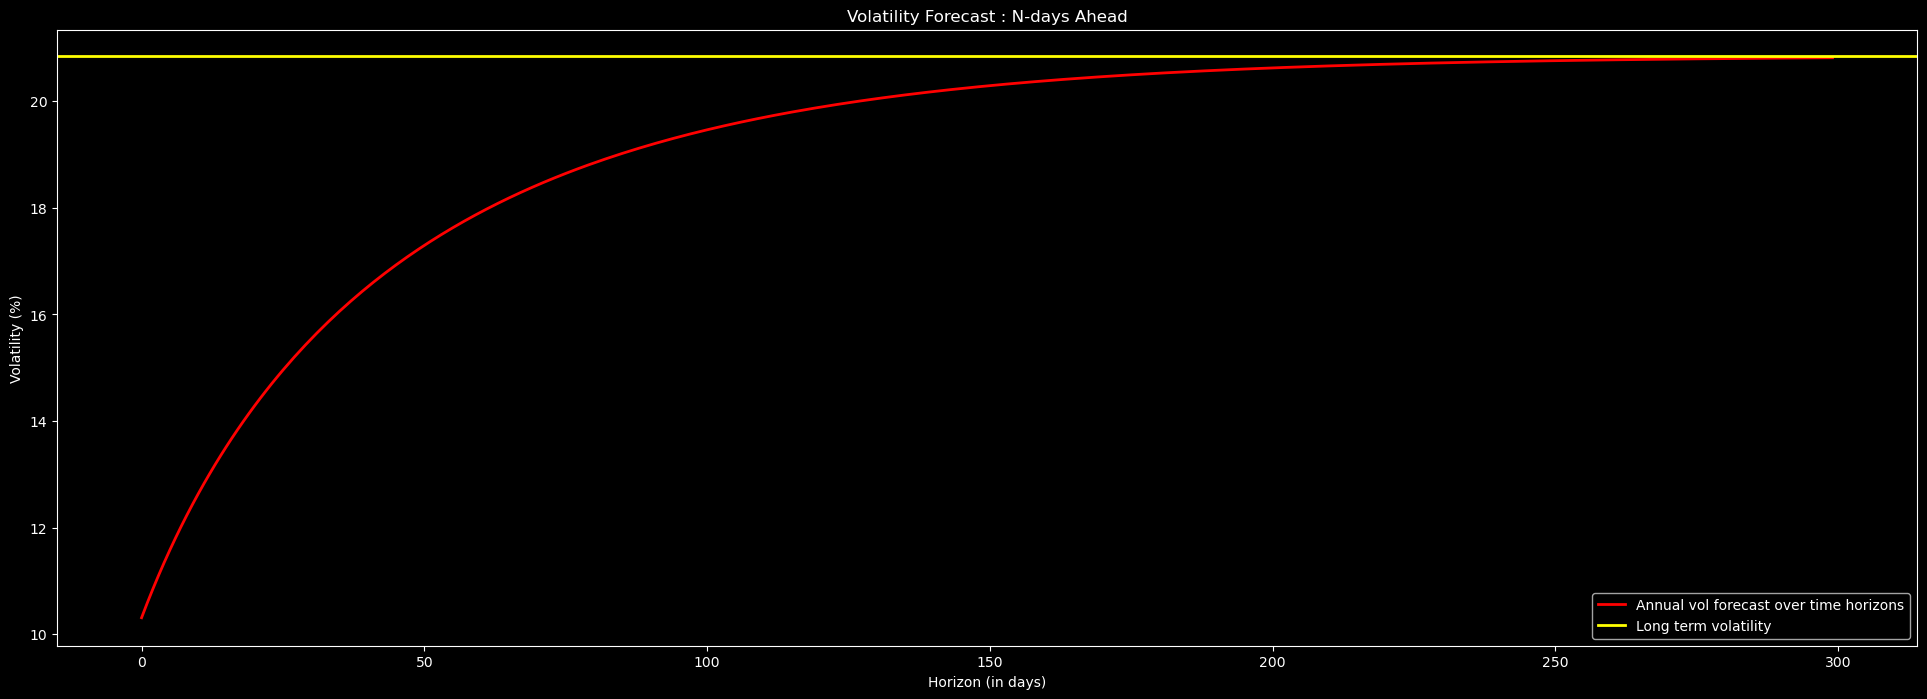

In [81]:
# Plot volatility forecast over different time horizon
plt.plot(fvol_annual[:300],label = 'Annual vol forecast over time horizons', color = 'red')
plt.title('Volatility Forecast : N-days Ahead')
plt.axhline(y=np.sqrt(longterm_variance*252)*100,label='Long term volatility', color = 'yellow')
plt.legend()
plt.xlabel('Horizon (in days)')
plt.ylabel('Volatility (%)')
plt.show()

## ARCH Toolbox

ARCH is one of the popular tools used for financial econometrics, written in Python - with Cython and/or Numba used to improve performance. We will now use arch_model to fit our GARCH model using this package.

In [ ]:
# basic information about model
# 'Log-Likelihood' shows 'fun' value from scipy optimized method

g1 = arch_model(y= returns,mean = 'Constant',vol = 'GARCH' ,p=1, q=1,o=0,dist = 'Normal')         # arch_model()
model= g1.fit()                                                                                    # fit()

print(model)                 

In [84]:
model.params                      # model.params
model.conf_int(alpha=.05)         # model.conf_int()

,lower,upper
mu,0.0788,0.0843
omega,-0.0003,0.0003
alpha[1],-0.0266,0.4267
beta[1],0.5107,1.0492


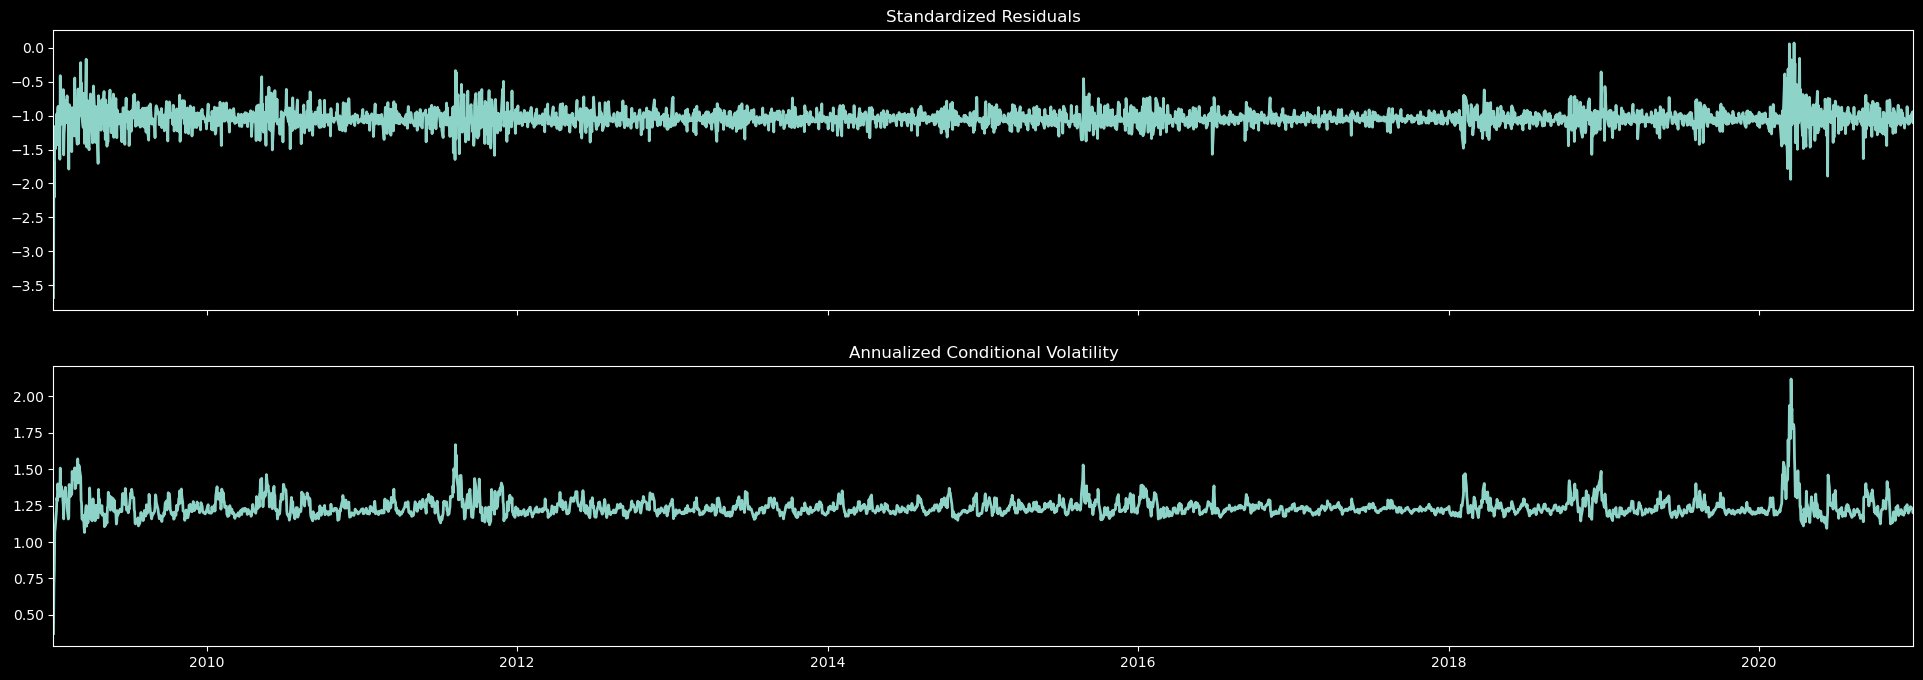

In [85]:
# Plot annualised vol
fig = model.plot(annualize='D')    # model.plot()

## References

[Tabulate](https://github.com/astanin/python-tabulate)

[ARCH](https://arch.readthedocs.io/en/latest/index.html)